In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
plt.style.use('default')
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False 
import pickle
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Conv1D,Conv2D,MaxPooling1D, MaxPooling2D, Flatten, Dense, Input, Dropout, LSTM, TimeDistributed, Reshape, BatchNormalization, Activation, concatenate
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')
cm = 1/2.54
# 字号
fontsize = 8
seed = 2025

## 数据集划分

In [143]:
with open (r'data\data.pkl','rb') as file:
    data = pickle.load(file)
    file.close()
data = data.dropna()

In [144]:
def add_feature(data):
    data['temp'] = data['id'].apply(lambda x: x.split('-')[0])
    data['charge_rate'] = data['id'].apply(lambda x: x.split('-')[1].split('_')[0])
    data['temp'] = data['temp'].astype(int)
    data['charge_rate'] = data['charge_rate'].astype(int)
    # 将temp、charge_rate移动到前面
    columns = data.columns.tolist()
    columns = columns[-2:] + columns[:-2]
    data = data[columns]
    # 0至-3列归一化，按列归一化
    data.iloc[:,0:-3] = data.iloc[:,0:-3].apply(lambda x: (x - x.min()) / (x.max() - x.min()))
    return data
data = add_feature(data)
data.head()

,temp,charge_rate,CC_0,CC_1,CC_2,CC_3,CC_4,CC_5,CC_6,CC_7,...,RE_144,RE_145,RE_146,RE_147,RE_148,RE_149,RE_150,cycle,capacity,id
0,0.0,1.0,0.969516,0.967475,0.965795,0.964514,0.963608,0.962994,0.962551,0.962151,...,0.700258,0.701156,0.702306,0.730984,0.765926,0.797114,0.824400,0.0,3246.857741,25-025_1-#1
1,0.0,1.0,0.971974,0.970147,0.968608,0.967405,0.966529,0.965928,0.965510,0.965174,...,0.694846,0.695779,0.697014,0.726300,0.761972,0.793825,0.821698,1.0,3247.637309,25-025_1-#1
2,0.0,1.0,0.970856,0.968799,0.967126,0.965873,0.965009,0.964445,0.964052,0.963695,...,0.711087,0.711518,0.712311,0.739858,0.773620,0.803873,0.830436,2.0,3248.392912,25-025_1-#1
3,0.0,1.0,0.975129,0.973471,0.972095,0.971036,0.970280,0.969767,0.969406,0.969099,...,0.711087,0.711715,0.712673,0.740302,0.774075,0.804293,0.830788,3.0,3247.386942,25-025_1-#1
4,0.0,1.0,0.974951,0.973180,0.971754,0.970700,0.969990,0.969547,0.969257,0.969001,...,0.713250,0.713952,0.714928,0.742309,0.775739,0.805613,0.831775,4.0,3246.083153,25-025_1-#1


In [145]:
# 按id分为训练、验证和测试集，比例为6:2:2
id = data['id'].unique()
np.random.seed(seed)
np.random.shuffle(id)
train_id = id[:int(len(id)*0.6)]
val_id = id[int(len(id)*0.6):int(len(id)*0.8)]
test_id = id[int(len(id)*0.8):]

In [146]:
print(data.columns[-3:])

Index(['cycle', 'capacity', 'id'], dtype='object')


In [147]:
# 根据id和列名获取数据集
def get_dataset(data, id, stage='CC'):
    dataset = data[data['id'].isin(id)]
    # 列名包括stage的列
    columns = [i for i in data.columns if stage in i]
    # columns添加'cycle', 'capacity', 'id'列
    columns = columns + ['temp', 'charge_rate'] + ['cycle', 'capacity', 'id']
    dataset = dataset[columns]
    return dataset
train_CC = get_dataset(data, train_id, 'CC')
val_CC = get_dataset(data, val_id, 'CC')
test_CC = get_dataset(data, test_id, 'CC')
train_CV = get_dataset(data, train_id, 'CV')
val_CV = get_dataset(data, val_id, 'CV')
test_CV = get_dataset(data, test_id, 'CV')
train_RE = get_dataset(data, train_id, 'RE')
val_RE = get_dataset(data, val_id, 'RE')
test_RE = get_dataset(data, test_id, 'RE')

## 模型

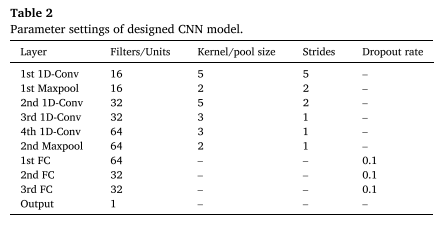  
使用A novel state of health estimation method for lithium-ion batteries based on constant-voltage charging partial data and convolutional neural network中的CNN

In [148]:
def CNN_model(input_shape):
    input_layer = Input(shape=input_shape)
    
    # 卷积层特征提取
    x = Conv1D(filters=16, kernel_size=5, strides=5, activation='relu')(input_layer)
    x = MaxPooling1D(pool_size=2, strides=2)(x)
    x = Conv1D(filters=32, kernel_size=5, strides=2, activation='relu')(x)
    x = Conv1D(filters=32, kernel_size=3, strides=1, activation='relu')(x)
    x = Conv1D(filters=64, kernel_size=3, strides=1, activation='relu')(x)
    x = MaxPooling1D(pool_size=2, strides=1)(x)
    
    # 【核心修复】：必须添加Flatten将3D张量压平为2D
    x = Flatten()(x)
    
    # 全连接层
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.1)(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.1)(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.1)(x)
    
    # 【优化】：回归任务输出层使用linear激活函数表现更稳定
    x = Dense(1, activation='linear')(x)
    
    model = Model(inputs=input_layer, outputs=x)
    
    # 【优化】：自定义优化器学习率，增加mae指标以更直观监测误差
    optimizer = Adam(learning_rate=0.001)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    
    return model

def model_train(model, train_data, val_data, epochs=200, save_path=None):
    train_X = train_data.iloc[:, :-3]
    train_y = train_data.iloc[:, -2]/3500.0
    val_X = val_data.iloc[:, :-3]
    val_y = val_data.iloc[:, -2]/3500.0
    
    scaler = StandardScaler()
    train_X = scaler.fit_transform(train_X)
    val_X = scaler.transform(val_X)
    
    train_X = train_X.reshape(train_X.shape[0], train_X.shape[1], 1)
    val_X = val_X.reshape(val_X.shape[0], val_X.shape[1], 1)
    
    callbacks = []
    
    # 策略1：早停（容忍25轮无提升后停止，并自动恢复验证集损失最低时的模型权重）
    early_stop = EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=1)
    callbacks.append(early_stop)
    
    # 策略2：学习率衰减（当验证集损失8轮不下降时，学习率减半，协助模型跳出局部最优）
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=1)
    callbacks.append(reduce_lr)
    
    # 策略3：只保存验证集效果最佳的模型
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True) # 确保保存路径的文件夹存在
        checkpoint = ModelCheckpoint(save_path, monitor='val_loss', save_best_only=True, verbose=1)
        callbacks.append(checkpoint)
        
    # 【优化】：显式指定 batch_size=32 并允许传入更长的 epoch，因为早停法会自动拦截过拟合
    model.fit(train_X, train_y,
              epochs=epochs,
              batch_size=32,
              validation_data=(val_X, val_y),
              callbacks=callbacks,
              verbose=1)
    
    # 由于早停设置了 restore_best_weights=True，此时的 model 已经是历史最优权重了
    return model

def model_eval(model, test_data):
    test_X = test_data.iloc[:, :-3]
    test_y = test_data.iloc[:, -2]/3500.0
    
    scaler = StandardScaler()
    test_X = scaler.fit_transform(test_X)
    test_X = test_X.reshape(test_X.shape[0], test_X.shape[1], 1)
    
    y_pred = model.predict(test_X)
    
    # 合并预测值、真实值、id和cycle
    y_pred = y_pred.reshape(y_pred.shape[0])
    y_pred = pd.DataFrame(y_pred, columns=['pred'])
    
    test_y = pd.DataFrame(test_y.values, columns=['true'])
    id_cycle = test_data[['id', 'cycle']].copy()
    id_cycle.reset_index(drop=True, inplace=True)
    
    # 合并结果
    result = pd.concat([id_cycle, y_pred, test_y], axis=1, ignore_index=True)
    result.columns = ['id', 'cycle', 'pred', 'true']
    result.reset_index(drop=True, inplace=True)
    
    return result

In [149]:
model_CC = CNN_model((train_CC.shape[1]-3, 1))
model_CV = CNN_model((train_CV.shape[1]-3, 1))
model_RE = CNN_model((train_RE.shape[1]-3, 1))
# CC
model_CC = model_train(model_CC, train_CC, val_CC, save_path=r'4-SOH_Estimation\深度学习模型结果\model_CC.h5')
result_CC = model_eval(model_CC, test_CC)
result_CC.to_csv(r'4-SOH_Estimation\深度学习模型结果\result_CC.csv', index=False)
# CV
model_CV = model_train(model_CV, train_CV, val_CV, save_path=r'4-SOH_Estimation\深度学习模型结果\model_CV.h5')
result_CV = model_eval(model_CV, test_CV)
result_CV.to_csv(r'4-SOH_Estimation\深度学习模型结果\result_CV.csv', index=False)
# RE
model_RE = model_train(model_RE, train_RE, val_RE, save_path=r'4-SOH_Estimation\深度学习模型结果\model_RE.h5')
result_RE = model_eval(model_RE, test_RE)
result_RE.to_csv(r'4-SOH_Estimation\深度学习模型结果\result_RE.csv', index=False)

Epoch 1/200
428/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1265 - mae: 0.2416
Epoch 1: val_loss improved from None to 0.00254, saving model to 4-SOH_Estimation\深度学习模型结果\model_CC.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0412 - mae: 0.1260 - val_loss: 0.0025 - val_mae: 0.0405 - learning_rate: 0.0010
Epoch 2/200
409/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0073 - mae: 0.0676
Epoch 2: val_loss improved from 0.00254 to 0.00132, saving model to 4-SOH_Estimation\深度学习模型结果\model_CC.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0068 - mae: 0.0649 - val_loss: 0.0013 - val_mae: 0.0270 - learning_rate: 0.0010
Epoch 3/200
430/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0055 - mae: 0.0582
Epoch 3: val_loss improved from 0.00132 to 0.00117, saving model to 4-SOH_Estimation\深度学习模型结果\model_CC.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0052 - mae: 0.0566 - val_loss: 0.0012 - val_mae: 0.0250 - learning_rate: 0.0010
Epoch 4/200
414/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0045 - mae: 0.0532
Epoch 4: val_loss improved from 0.00117 to 0.00109, saving model to 4-SOH_Estimation\深度学习模型结果\model_CC.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0043 - mae: 0.0518 - val_loss: 0.0011 - val_mae: 0.0252 - learning_rate: 0.0010
Epoch 5/200
420/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0038 - mae: 0.0482
Epoch 5: val_loss improved from 0.00109 to 0.00098, saving model to 4-SOH_Estimation\深度学习模型结果\model_CC.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0037 - mae: 0.0474 - val_loss: 9.8451e-04 - val_mae: 0.0222 - learning_rate: 0.0010
Epoch 6/200
425/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0034 - mae: 0.0456
Epoch 6: val_loss improved from 0.00098 to 0.00089, saving model to 4-SOH_Estimation\深度学习模型结果\model_CC.h5


... (37 outputs left out)

431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 3.4671e-04 - mae: 0.0142 - val_loss: 2.5338e-04 - val_mae: 0.0116 - learning_rate: 5.0000e-04
Epoch 14/200
420/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.9366e-04 - mae: 0.0130
Epoch 14: val_loss improved from 0.00025 to 0.00025, saving model to 4-SOH_Estimation\深度学习模型结果\model_RE.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2.8343e-04 - mae: 0.0128 - val_loss: 2.4819e-04 - val_mae: 0.0122 - learning_rate: 5.0000e-04
Epoch 15/200
430/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.5336e-04 - mae: 0.0121
Epoch 15: val_loss did not improve from 0.00025
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2.4486e-04 - mae: 0.0119 - val_loss: 2.7300e-04 - val_mae: 0.0126 - learning_rate: 5.0000e-04
Epoch 16/200
427/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.1901e-04 - mae: 0.0111
Epoch 16: val_loss improved from 0.00025 to 0.00024, saving model to 4-SOH_Estimation\深度学习模型结果\model_RE.h5


431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2.1369e-04 - mae: 0.0109 - val_loss: 2.3677e-04 - val_mae: 0.0116 - learning_rate: 5.0000e-04
Epoch 17/200
408/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.9119e-04 - mae: 0.0103
Epoch 17: val_loss did not improve from 0.00024
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.8376e-04 - mae: 0.0101 - val_loss: 2.5085e-04 - val_mae: 0.0121 - learning_rate: 5.0000e-04
Epoch 18/200
429/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.7194e-04 - mae: 0.0098
Epoch 18: val_loss did not improve from 0.00024
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.6754e-04 - mae: 0.0096 - val_loss: 2.4834e-04 - val_mae: 0.0122 - learning_rate: 5.0000e-04
Epoch 19/200
419/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.5814e-04 - mae: 0.0093
Epoch 19: val_loss did not improve from 0.00024
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5671e-04 - mae: 0.0092 - val_loss: 2.4141e-04 - val_mae: 0.0120 - learning_rate: 5.0000e-04
Epoch 20/200
424/431 ━━

431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.2102e-04 - mae: 0.0081 - val_loss: 2.3222e-04 - val_mae: 0.0117 - learning_rate: 2.5000e-04
Epoch 27/200
429/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2312e-04 - mae: 0.0082
Epoch 27: val_loss did not improve from 0.00023
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2367e-04 - mae: 0.0082 - val_loss: 2.3951e-04 - val_mae: 0.0120 - learning_rate: 2.5000e-04
Epoch 28/200
423/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2339e-04 - mae: 0.0082
Epoch 28: val_loss did not improve from 0.00023
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2395e-04 - mae: 0.0083 - val_loss: 2.4906e-04 - val_mae: 0.0121 - learning_rate: 2.5000e-04
Epoch 29/200
411/431 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2187e-04 - mae: 0.0081
Epoch 29: val_loss did not improve from 0.00023
431/431 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.2053e-04 - mae: 0.0081 - val_loss: 2.5521e-04 - val_mae: 0.0122 - learning_rate: 2.5000e-04
Epoch 30/200
430/431 ━━